<a href="https://colab.research.google.com/github/nour2344/RoadAnomaly-DeepLearning/blob/main/notebooks/01_data_understanding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import drive

drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [2]:

from pathlib import Path

# Chemin du dataset dans Google Drive
dataset_dir = Path(
    "/content/drive/MyDrive/deep learning P/RoadAnomaly"
)

print("Dataset exists:", dataset_dir.exists())

# Afficher le contenu du dossier
if dataset_dir.exists():
    for item in dataset_dir.iterdir():
        print(item.name)


Dataset exists: True
RoadAnomaly


*Étape* 2 — Localiser automatiquement le dossier frames

In [3]:

# Chercher le dossier frames
frames_folders = [
    p for p in dataset_dir.rglob("frames")
    if p.is_dir()
]

print("Frames folders:", frames_folders)

if not frames_folders:
    raise FileNotFoundError("Dossier frames introuvable")

frames_dir = frames_folders[0]

print("Frames path:", frames_dir)

# Compter les images et les masques
images = list(frames_dir.glob("*.webp"))
masks = list(frames_dir.glob("*.labels/labels_semantic.png"))

print("Number of images:", len(images))
print("Number of masks:", len(masks))


Frames folders: [PosixPath('/content/drive/MyDrive/deep learning P/RoadAnomaly/RoadAnomaly/frames')]
Frames path: /content/drive/MyDrive/deep learning P/RoadAnomaly/RoadAnomaly/frames
Number of images: 60
Number of masks: 60


2. Étape suivante — Analyse descriptive des données

In [4]:

from PIL import Image
import numpy as np
import pandas as pd

records = []

for image_path in sorted(images):
    mask_path = (
        frames_dir / f"{image_path.stem}.labels"
        / "labels_semantic.png"
    )

    with Image.open(image_path) as img:
        width, height = img.size

    mask_exists = mask_path.exists()
    mask_aligned = False
    mask_values = []
    anomaly_percent = np.nan

    if mask_exists:
        with Image.open(mask_path) as m:
            mask = np.array(m)
            mask_aligned = m.size == (width, height)

        if mask.ndim == 2:
            mask_values = np.unique(mask).tolist()
            anomaly_percent = 100 * np.mean(mask == 2)

    records.append({
        "Image": image_path.name,
        "Width": width,
        "Height": height,
        "Mask_exists": mask_exists,
        "Mask_aligned": mask_aligned,
        "Mask_values": mask_values,
        "Anomaly_%": anomaly_percent
    })

df = pd.DataFrame(records)

print("Nombre d'images :", len(df))
print("Images avec masque :", df["Mask_exists"].sum())
print("Masques alignés :", df["Mask_aligned"].sum())

print("\nDimensions des images :")
print(df.groupby(["Width", "Height"]).size())

print("\nPourcentage moyen de pixels anormaux :")
print(df["Anomaly_%"].mean())

display(df.head(10))


Nombre d'images : 60
Images avec masque : 60
Masques alignés : 60

Dimensions des images :
Width  Height
1280   720       60
dtype: int64

Pourcentage moyen de pixels anormaux :
9.849560546875


,Image,Width,Height,Mask_exists,Mask_aligned,Mask_values,Anomaly_%
0,animals01_Guiguinto_railway_station_Calves.webp,1280,720,True,True,"[0, 2]",6.707574
1,animals02_Zagori_On_the_road_to_Papigko.webp,1280,720,True,True,"[0, 2]",0.799154
2,animals03_Zebras_in_the_road.webp,1280,720,True,True,"[0, 2]",23.374349
3,animals04_17_animal_casualties_so_far_in_2006....,1280,720,True,True,"[0, 2]",6.602105
4,animals05_cows_near_Phonsavan_Laos.webp,1280,720,True,True,"[0, 2]",14.610135
5,animals06_sheep_roads_lambs.webp,1280,720,True,True,"[0, 2]",36.845812
6,animals07_Aihole_Pattadakal.webp,1280,720,True,True,"[0, 2]",8.195530
7,animals08_on_the_main_street_of_village_Lin_Al...,1280,720,True,True,"[0, 2]",1.763346
8,animals09_working_together.webp,1280,720,True,True,"[0, 2]",42.328559
9,animals10_bovine_cattle_beside_road.webp,1280,720,True,True,"[0, 2]",2.773112


3. Visualisation d'une image et de son masque

Image : animals01_Guiguinto_railway_station_Calves.webp
Valeurs du masque : [0 2]


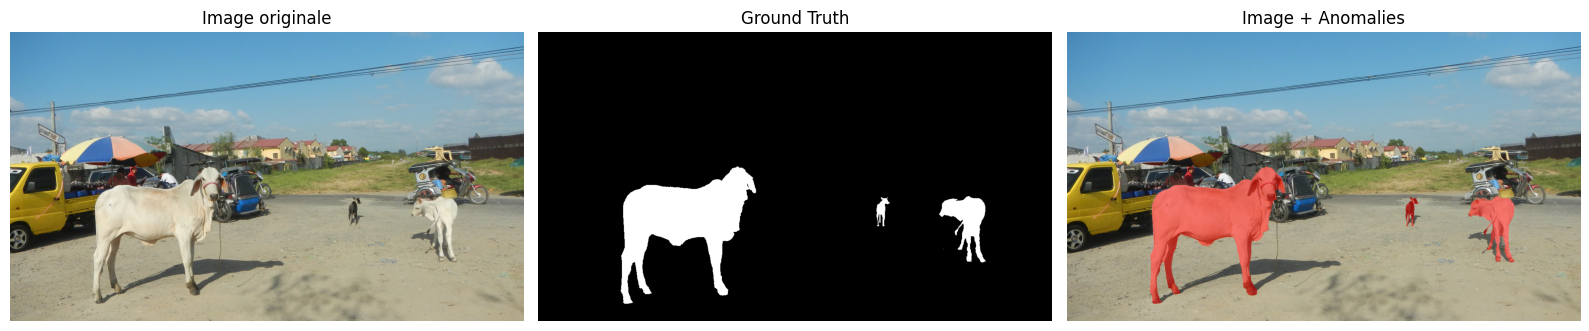

In [5]:

import matplotlib.pyplot as plt

# Choisir une paire image-masque valide
valid = df[df["Mask_exists"] & df["Mask_aligned"]]

if valid.empty:
    raise ValueError("Aucune paire image-masque valide.")

image_path = frames_dir / valid.iloc[0]["Image"]
mask_path = (
    frames_dir / f"{image_path.stem}.labels"
    / "labels_semantic.png"
)

image = np.array(Image.open(image_path).convert("RGB"))
mask = np.array(Image.open(mask_path))

print("Image :", image_path.name)
print("Valeurs du masque :", np.unique(mask))

# Convention RoadAnomaly : classe 2 = anomalie
binary_mask = (mask == 2).astype(np.uint8)

overlay = image.copy()
overlay[binary_mask == 1] = (
    0.5 * image[binary_mask == 1]
    + 0.5 * np.array([255, 0, 0])
).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(image)
axes[0].set_title("Image originale")

axes[1].imshow(binary_mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground Truth")

axes[2].imshow(overlay)
axes[2].set_title("Image + Anomalies")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


4. Étape suivante — Data Exploration : distribution des anomalies

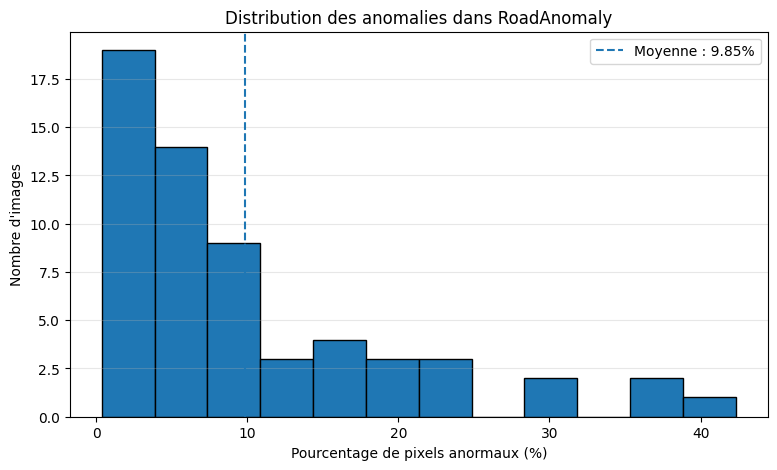

Valeurs rencontrées : [0, 2]


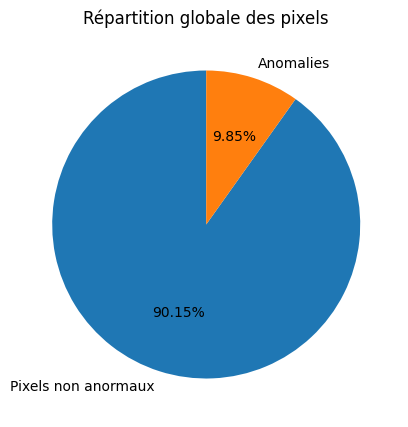

Pixels anormaux : 9.85%
Pixels non anormaux : 90.15%


In [6]:

import matplotlib.pyplot as plt
import numpy as np

# Graphique 1 : distribution des anomalies
plt.figure(figsize=(9, 5))

plt.hist(
    df["Anomaly_%"].dropna(),
    bins=12,
    edgecolor="black"
)

plt.axvline(
    df["Anomaly_%"].mean(),
    linestyle="--",
    label=f"Moyenne : {df['Anomaly_%'].mean():.2f}%"
)

plt.xlabel("Pourcentage de pixels anormaux (%)")
plt.ylabel("Nombre d'images")
plt.title("Distribution des anomalies dans RoadAnomaly")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

# Graphique 2 : répartition globale des pixels
total_anomaly = 0
total_pixels = 0
all_values = set()

for image_path in images:
    mask_path = (
        frames_dir / f"{image_path.stem}.labels"
        / "labels_semantic.png"
    )

    if mask_path.exists():
        mask = np.array(Image.open(mask_path))
        all_values.update(np.unique(mask).tolist())
        total_anomaly += np.count_nonzero(mask == 2)
        total_pixels += mask.size

print("Valeurs rencontrées :", sorted(all_values))

if not all_values.issubset({0, 2}):
    print("Attention : autres classes à examiner.")

anomaly_pct = 100 * total_anomaly / total_pixels
normal_pct = 100 - anomaly_pct

plt.figure(figsize=(6, 5))
plt.pie(
    [normal_pct, anomaly_pct],
    labels=["Pixels non anormaux", "Anomalies"],
    autopct="%1.2f%%",
    startangle=90
)
plt.title("Répartition globale des pixels")
plt.show()

print(f"Pixels anormaux : {anomaly_pct:.2f}%")
print(f"Pixels non anormaux : {normal_pct:.2f}%")


3. Étape suivante — Explorer les catégories d'anomalies

Category
Animals       31
Obstacles     15
Cones          8
Lost tires     3
Vehicles       3
Name: count, dtype: int64


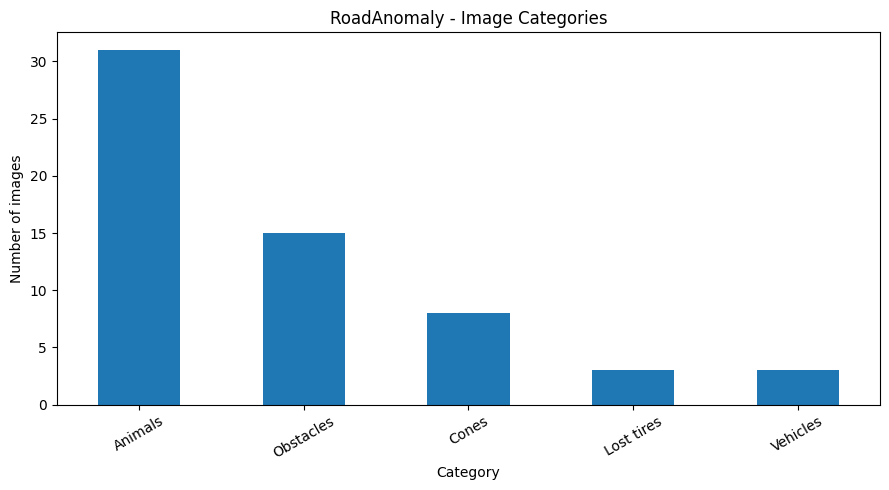

In [9]:

from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

# Extraire une catégorie indicative du nom du fichier
def get_category(filename):
    name = filename.lower()

    if name.startswith("animals"):
        return "Animals"
    elif name.startswith("cones"):
        return "Cones"
    elif name.startswith("obstacles"):
        return "Obstacles"
    elif name.startswith("vehicle"):
        return "Vehicles"
    elif name.startswith("lost_tires"):
        return "Lost tires"
    else:
        return "Other"

df["Category"] = df["Image"].apply(get_category)

print(df["Category"].value_counts())

df["Category"].value_counts().plot(
    kind="bar",
    figsize=(9, 5),
    title="RoadAnomaly - Image Categories"
)

plt.xlabel("Category")
plt.ylabel("Number of images")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


4. Dernière étape : vérification de la qualité des données

In [8]:

print("=== DATA QUALITY REPORT ===")

print("Images analysées :", len(df))

print("Masques manquants :",
      (~df["Mask_exists"]).sum())

print("Masques non alignés :",
      (~df["Mask_aligned"]).sum())

print("Valeurs manquantes :")
print(df.isnull().sum())

print("Noms d'images dupliqués :",
      df["Image"].duplicated().sum())

print("\nStatistiques sur les anomalies :")
print(df["Anomaly_%"].describe())

print("\nImages avec plus de 30 % de pixels anormaux :")
display(df[df["Anomaly_%"] > 30][
    ["Image", "Anomaly_%"]
])


=== DATA QUALITY REPORT ===
Images analysées : 60
Masques manquants : 0
Masques non alignés : 0
Valeurs manquantes :
Image           0
Width           0
Height          0
Mask_exists     0
Mask_aligned    0
Mask_values     0
Anomaly_%       0
Category        0
dtype: int64
Noms d'images dupliqués : 0

Statistiques sur les anomalies :
count    60.000000
mean      9.849561
std      10.059954
min       0.374674
25%       1.801595
50%       6.622938
75%      13.795763
max      42.328559
Name: Anomaly_%, dtype: float64

Images avec plus de 30 % de pixels anormaux :


,Image,Anomaly_%
5,animals06_sheep_roads_lambs.webp,36.845812
8,animals09_working_together.webp,42.328559
15,animals16_Donkeys_of_Morocco.webp,31.175673
23,animals24_Sheep_Herders_Block_the_Road_Kaleyba...,36.716146
